# Analysis of spike triggered frequency spectrum

This notebook processes the frequency spectrum of spike triggered time intervals.

## Initialization - don't change

In [20]:
import sys
sys.path.append('..')

from workflows.run_util.io import collect_paths_from_table

## Color settings

Set the colors that will be used for coloring the markers on the strip plot and the cellwise average firing frequency curve.

In [21]:
palette = {
    'cell_type': {
        'PYR_L2-3': '#803300ff',
        'PYR_L4-6': '#502d16ff',
        'RSI_L2-3': '#ff48a3ff',
        'RSI_L4-6': '#800080ff',
        'FSI_L2-3': '#d54500ff',
        'FSI_L4-6': '#7a0000ff'
    },
    'spike_type': {
        'AIS-AP': "#3150B7",
        'RA-AP': '#00ff00',
        'UNKNOWN': '#000000b2'
    }
}

## Input-output settings

Set the Excel table containing the cell attributes, grouping and selector information.

In [22]:
input_param = {
    'mode': 'table',
    'table_path': 'E:\\Data\\BogiSejtek\\20251007\\data\\invivo\\Preprocessed\\data_invivo.xlsx',
    'select_rules': [
        {'selected': 1}
    ]
}

Set the output base directory path. All results of this analysis (cellwise aggregated tables, grouped results, figures, statistics) is going to saved there.

In [23]:
output_path = 'E:\\Data\\BogiSejtek\\20251007\\data\\invivo\\Preprocessed\\SpikeTriggeredWavelet'

In [24]:
spike_types = ['AIS-AP', 'UNKNOWN', 'RA-AP']

## Run analysis

Collect input files according to the table.

In [25]:
from pathlib import Path
import pandas as pd

frames = []
for file_name in (Path(output_path) / '01_results').glob('*_spike_freq_spectrum.xlsx'):
    frames.append(pd.read_excel(file_name))
pool_data = pd.concat(frames, ignore_index=True)
pool_data['spike_type'] = pd.Categorical(
    pool_data['spike_type'],
    categories=spike_types,
    ordered=True
)


In [26]:
X, y = pool_data.iloc[:, 1:].values, pool_data['spike_type'].cat.codes
X_zscore = (X - X.mean(axis=0)) / X.std(axis=0)

In [27]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_zscore)
pd_score_frame = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pd_score_frame['spike_type'] = pool_data['spike_type']

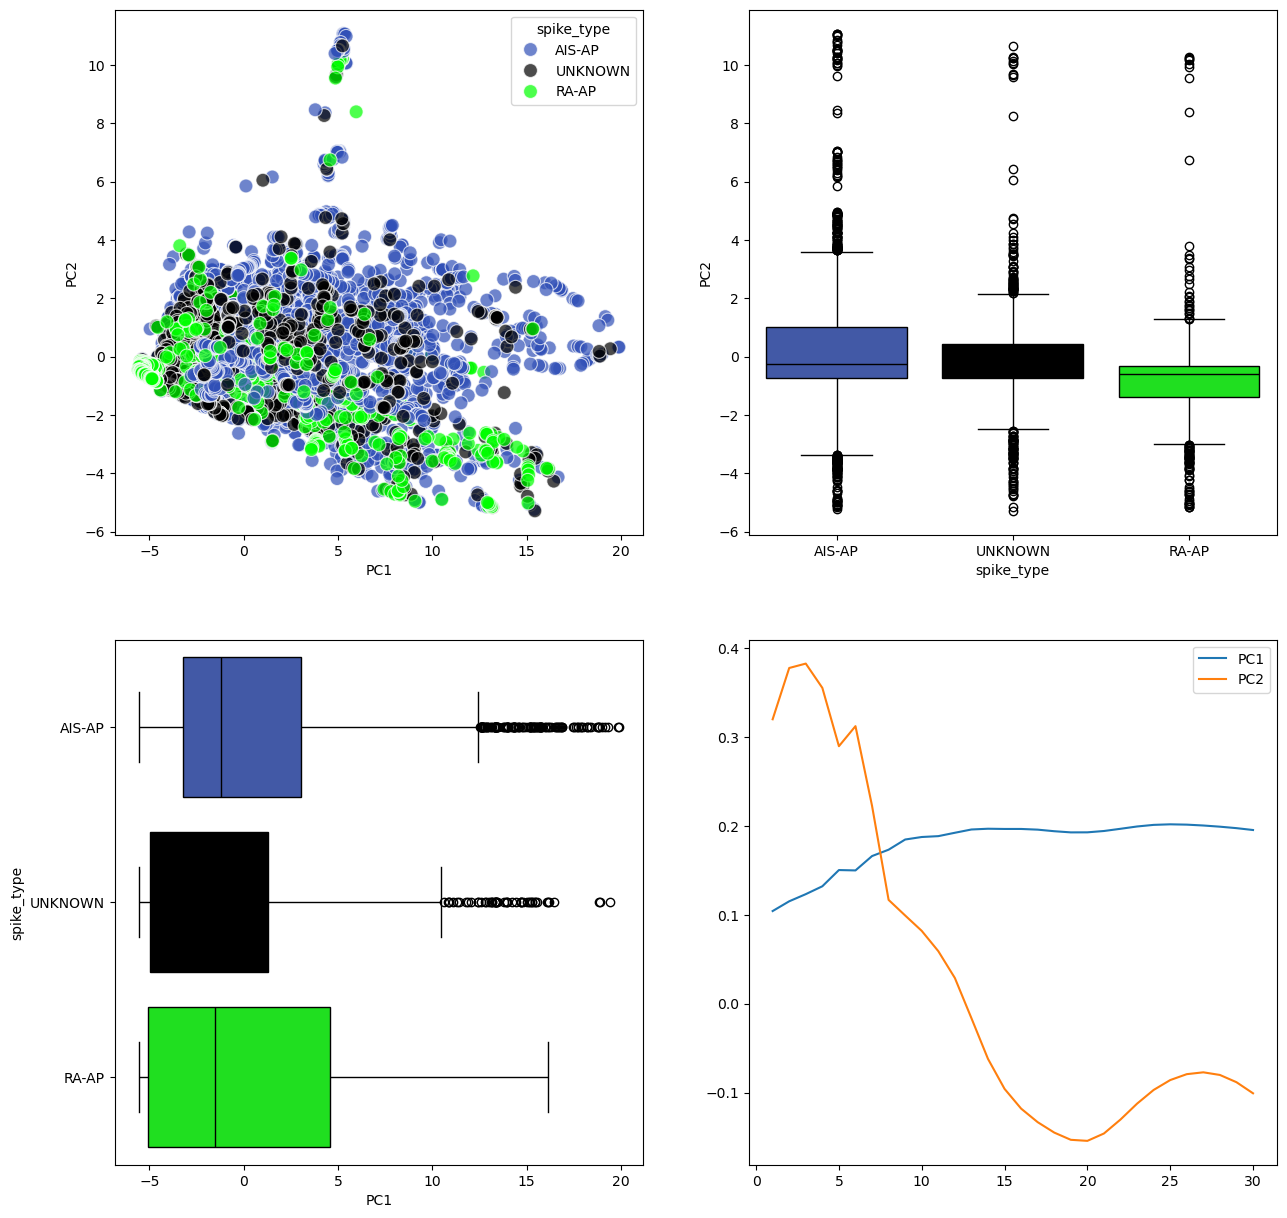

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(15, 15))
sns.scatterplot(
    data=pd_score_frame,
    x='PC1',
    y='PC2',
    hue='spike_type',
    palette=palette['spike_type'],
    s=100,
    alpha=0.7,
    ax=axes[0, 0]
)
sns.boxplot(
    data=pd_score_frame,
    x='PC1',
    y='spike_type',
    hue='spike_type',
    orient='h',
    palette=palette['spike_type'],
    ax=axes[1, 0],
)
sns.boxplot(
    data=pd_score_frame,
    y='PC2',
    x='spike_type',
    hue='spike_type',
    orient='v',
    palette=palette['spike_type'],
    ax=axes[0, 1],
)
axes[1, 1].plot(
    range(1, 31),
    pca.components_[0, :],
    '-',
    label='PC1'
)
axes[1, 1].plot(
    range(1, 31),
    pca.components_[1, :],
    '-',
    label='PC2'
)
axes[1, 1].legend()
plt.show()